CONTEXT WINDOW COMPARISON

DOG
Window 2: ['barks', 'loudly', 'holds', 'the', 'the', 'ran', 'across']
Window 3: ['barks', 'loudly', 'kennel', 'holds', 'the', 'the', 'ran', 'across', 'the']

CAT
Window 2: ['sleeps', 'quietly', 'the', 'has', 'whiskers', 'the', 'slept', 'near']
Window 3: ['sleeps', 'quietly', 'the', 'has', 'whiskers', 'the', 'slept', 'near', 'the']

CAR
Window 2: ['drives', 'the', 'the', 'moves', 'down', 'the', 'stopped', 'near']
Window 3: ['drives', 'the', 'road', 'the', 'moves', 'down', 'the', 'the', 'stopped', 'near', 'the']

TRUCK
Window 2: ['carries', 'cargo', 'powers', 'the', 'the', 'hauls', 'heavy']
Window 3: ['carries', 'cargo', 'engine', 'powers', 'the', 'the', 'hauls', 'heavy', 'loads']



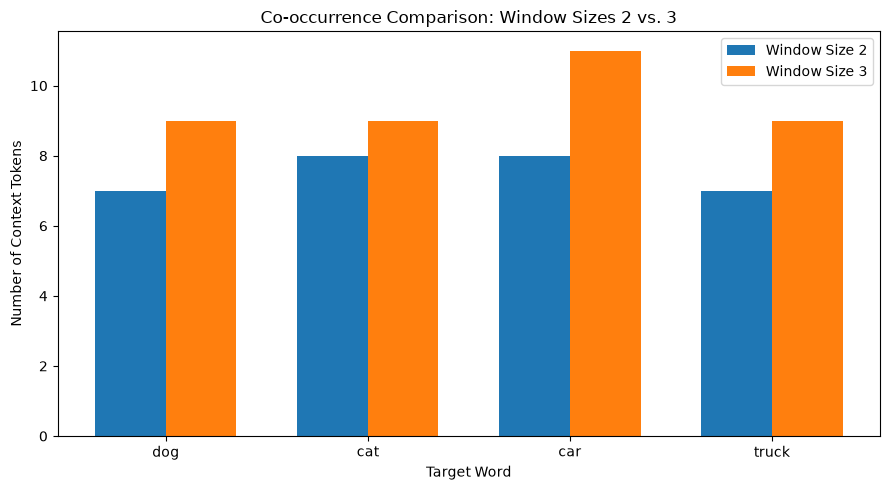

Phase 4 completed successfully.


In [ ]:
from collections import defaultdict

import matplotlib.pyplot as plt

# Same corpus as the original Module 3 example
corpus = [
    "A dog barks loudly.",
    "The puppy runs in the yard.",
    "A canine wears a leash.",
    "The kennel holds the dog.",
    "The dog ran across the yard.",
    "The puppy ran across the yard.",
    "A cat sleeps quietly.",
    "The kitten plays with yarn.",
    "A feline purrs softly.",
    "The cat has whiskers.",
    "The cat slept near the window.",
    "The kitten slept near the window.",
    "A car drives on the road.",
    "The sedan parks in the garage.",
    "A vehicle has four wheels.",
    "The car moves down the highway.",
    "The car stopped near the garage.",
    "The sedan stopped near the garage.",
    "A truck carries cargo.",
    "The pickup pulls a trailer.",
    "The engine powers the truck.",
    "The truck hauls heavy loads.",
]


def tokenize(text):
    """Convert text into cleaned tokens."""
    tokens = text.lower().split()
    return [t.strip(".,:;!?()[]\"'") for t in tokens if len(t) > 2]


def analyze_context(window_size):
    """Calculate word co-occurrence using the selected context window."""
    co_occurrence = defaultdict(list)

    for text in corpus:
        tokens = tokenize(text)

        for i, token in enumerate(tokens):
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)

            for context_word in tokens[start:end]:
                if context_word != token:
                    co_occurrence[token].append(context_word)

    return co_occurrence


# Compare the original window size of 2 with a larger window of 3
window_2 = analyze_context(2)
window_3 = analyze_context(3)

targets = ["dog", "cat", "car", "truck"]

print("CONTEXT WINDOW COMPARISON\n")

for target in targets:
    print(f"{target.upper()}")
    print(f"Window 2: {window_2[target]}")
    print(f"Window 3: {window_3[target]}")
    print()

# Visualize the number of context tokens
counts_2 = [len(window_2[word]) for word in targets]
counts_3 = [len(window_3[word]) for word in targets]

x = range(len(targets))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar([i - width / 2 for i in x], counts_2, width, label="Window Size 2")
plt.bar([i + width / 2 for i in x], counts_3, width, label="Window Size 3")

plt.xticks(list(x), targets)
plt.xlabel("Target Word")
plt.ylabel("Number of Context Tokens")
plt.title("Co-occurrence Comparison: Window Sizes 2 vs. 3")
plt.legend()
plt.tight_layout()
plt.show()

print("Phase 4 completed successfully.")